In [3]:
import torch
import yaml
import matplotlib.pyplot as plt
from transformers import BertTokenizer

from src.data_utils.corpus import Corpus
from src.retrievers.models.encoder import TransformerEncoder
from src.training.trainer import build_pairs, Trainer

torch.manual_seed(1)   


We introduce the dataset

In [ ]:
corpus = Corpus(dataset_name='fiqa', base_dir='./retrieval_data')

DatasetDict({
    train: Dataset({
        features: ['question', 'text', 'query_id', 'document_id'],
        num_rows: 5500
    })
    validation: Dataset({
        features: ['question', 'text', 'query_id', 'document_id'],
        num_rows: 500
    })
    test: Dataset({
        features: ['question', 'text', 'query_id', 'document_id'],
        num_rows: 648
    })
})

## 3. Construir las parejas (pregunta, pasaje) para entrenar
`build_pairs` aplana el dataset: si una pregunta tiene 3 pasajes relevantes, salen 3 parejas.

In [6]:
pairs = build_pairs(corpus.train)
print('nº de parejas de train:', len(pairs))
pairs[0][0], pairs[0][1][:200]

nº de parejas de train: 14166


('What is considered a business expense on a business trip?',
 'The IRS Guidance pertaining to the subject.  In general the best I can say is your business expense may be deductible.  But it depends on the circumstances and what it is you want to deduct. Travel Ta')

## 4. Tokenizer y los dos encoders
Usamos nuestro `TransformerEncoder` (`src/retrievers/models/encoder.py`): embedding + K capas de transformer + pooling, **sin preentrenar** (pesos aleatorios). Su tamaño se lee de `config/model/encoder.yaml`.

- **Tokenizer:** el de `bert-base-uncased`. Solo convierte texto en ids; su vocabulario (30.522 tokens) coincide con el tamaño por defecto del embedding de `BertConfig`.
- **Dos encoders independientes:** uno para las preguntas (`g_φ`) y otro para los pasajes (`f_θ`). Son dos llamadas separadas, así que tienen parámetros distintos.

In [7]:
with open('config/model/encoder.yaml') as f:
    cfg_model = yaml.safe_load(f)
print('config del encoder:', cfg_model)

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")

query_encoder = TransformerEncoder(n_layers=cfg_model['n_layers'],
                                   n_heads=cfg_model['n_heads'],
                                   emb_dim=cfg_model['emb_dim'],
                                   hidden_dim=cfg_model['hidden_dim'],
                                   feed_forward_dim=cfg_model['feed_forward_dim'],
                                   pooling_type=cfg_model['pooling_type'])

passage_encoder = TransformerEncoder(n_layers=cfg_model['n_layers'],
                                     n_heads=cfg_model['n_heads'],
                                     emb_dim=cfg_model['emb_dim'],
                                     hidden_dim=cfg_model['hidden_dim'],
                                     feed_forward_dim=cfg_model['feed_forward_dim'],
                                     pooling_type=cfg_model['pooling_type'])

print('¿Son el mismo objeto?', query_encoder is passage_encoder)
print('parámetros por encoder:', sum(p.numel() for p in query_encoder.parameters()))

config del encoder: {'pooling_type': 'cls', 'emb_dim': 128, 'hidden_dim': 32, 'n_heads': 4, 'n_layers': 6, 'feed_forward_dim': 768}
¿Son el mismo objeto? False
parámetros por encoder: 5573760


## 5. Crear el Trainer y entrenar
Prueba rápida con las primeras 200 parejas de train.

- Al final de **cada época**, el `Trainer` calcula la **loss de validación** (media sobre las parejas de `corpus.val`, sin tocar los pesos) y la guarda en `trainer.val_losses`.
- Al final de **todo el entrenamiento** (tras la última época), guarda los pesos finales de los dos encoders en `save_dir`.

In [8]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
SAVE_DIR = 'outputs/dpr_weights'

val_pairs = build_pairs(corpus.val)
print('nº de parejas de validación:', len(val_pairs))

trainer = Trainer(query_encoder, passage_encoder, tokenizer, device, lr=2e-5, batch_size=16, epochs=2)
loss = trainer.train(query_encoder, passage_encoder, pairs[:200],
                     val_dataset=val_pairs[:200],
                     save_dir=SAVE_DIR)
print('loss del último batch:', loss.item())
print('val loss por epoch:', trainer.val_losses)

nº de parejas de validación: 1238
epoch 1/2 | step 0/13 | loss 6.0131
epoch 1/2 | step 10/13 | loss 6.3974
epoch 1/2 | val loss 2.7230
epoch 2/2 | step 0/13 | loss 5.3162
epoch 2/2 | step 10/13 | loss 3.7331
epoch 2/2 | val loss 2.7224
Final weights stored in outputs/dpr_weights
loss del último batch: 4.767613887786865
val loss por epoch: [2.7230401589320254, 2.7223720917334924]


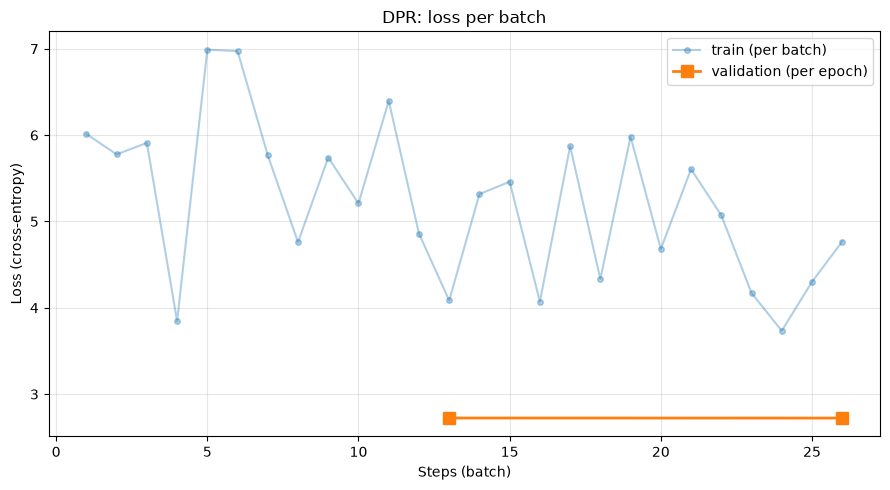

In [9]:
import numpy as np

losses = np.array(trainer.losses)
steps = np.arange(1, len(losses) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(steps, losses, color='tab:blue', alpha=0.35, marker='o', markersize=4, label='train (per batch)')

# validation loss: one point at the end of each epoch
steps_per_epoch = len(losses) // trainer.epochs
val_steps = [(e + 1) * steps_per_epoch for e in range(len(trainer.val_losses))]
ax.plot(val_steps, trainer.val_losses, color='tab:orange', marker='s', markersize=8, linewidth=2, label='validation (per epoch)')

ax.set_title('DPR: loss per batch')
ax.set_xlabel('Steps (batch)')
ax.set_ylabel('Loss (cross-entropy)')
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Comprobar los pesos guardados
El `Trainer` guarda los pesos finales en `SAVE_DIR` (`query_encoder.pt` y `document_encoder.pt`). Comprobamos que lo que hay en el archivo es idéntico al modelo que tenemos en memoria. Si da `True`, guardar funciona.

Para cargarlos más adelante: crear el `TransformerEncoder` con la misma config y hacer `encoder.load_state_dict(torch.load(ruta))`.

In [10]:
guardado_q = torch.load(f'{SAVE_DIR}/query_encoder.pt', map_location='cpu')
guardado_p = torch.load(f'{SAVE_DIR}/document_encoder.pt', map_location='cpu')

iguales_q = all(torch.equal(guardado_q[k], v.cpu()) for k, v in query_encoder.state_dict().items())
iguales_p = all(torch.equal(guardado_p[k], v.cpu()) for k, v in passage_encoder.state_dict().items())
print('pesos en:', SAVE_DIR)
print('query_encoder   idéntico al de memoria:', iguales_q)
print('passage_encoder idéntico al de memoria:', iguales_p)

pesos en: outputs/dpr_weights
query_encoder   idéntico al de memoria: True
passage_encoder idéntico al de memoria: True
